# Taller: Backpropagation y Optimización

### Redes Neuronales — Funciones de pérdida, backpropagation y optimizadores (SGD, Momentum, Adam) con NumPy

**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 17-11-2026

> **Cómo usar este documento:** este archivo es una **guía de referencia**, no un notebook interactivo.
> Reproduce el código en tu propio notebook (Google Colab o Jupyter), en el mismo orden de bloques,
> usando los archivos CSV que se entregan junto con esta guía. Las respuestas a las preguntas
> se escriben en celdas de texto de **tu** notebook.

## Objetivos del taller

Al finalizar este taller el estudiante será capaz de:

* Programar con NumPy las funciones de pérdida **MSE** y **entropía cruzada binaria**.
* Comprobar con código el **paso de backpropagation** calculado a mano en clase.
* Entrenar una red neuronal desde cero con **mini-batch SGD**, **Momentum** y **Adam**, y comparar sus curvas de pérdida.
* Analizar el efecto de la **tasa de aprendizaje** (η) en una red de regresión.

## Datasets (sintéticos, sin valores nulos)

| Parte | Archivo | Filas | Entradas | Salida |
| --- | --- | --- | --- | --- |
| A | estudiantes_aprobacion.csv | 200 estudiantes | horas_estudio, asistencia_pct | aprueba (1 = aprueba) · clasificación |
| B | credito_ecuador.csv | 200 clientes | ingresos_norm, historial_norm (ya entre 0 y 1) | puntaje_credito (0 a 1) · regresión |

El archivo de la Parte A es el mismo de los talleres de Arquitectura de Redes Neuronales y de Funciones de Activación.

## Estructura del taller

| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Datos y funciones de activación |
| A2 | Guiado | Funciones de pérdida: MSE y entropía cruzada binaria |
| A3 | Guiado | Un paso de backpropagation: el ejemplo de clase |
| A4 | Guiado | forward() y backward() para muchos ejemplos |
| A5 | Guiado | Bucle de entrenamiento con mini-lotes y tres optimizadores |
| A6 | Guiado | SGD vs Momentum vs Adam con los 200 estudiantes |
| B1–B5 | Autónomo | Red de regresión para el puntaje de crédito |

## Rúbrica de evaluación (10 puntos)

| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A6 (guiados) | Reproducidos completos y sin errores en tu notebook + respuestas a las preguntas de la Parte A | 1.5 |
| B1 · Datos | Código correcto + formas verificadas | 1.0 |
| B2 · Forward y backward de regresión | Funciones correctas + verificación del gradiente + respuestas | 2.0 |
| B3 · Entrenamiento con 4 tasas de aprendizaje | Bucle correcto + tabla de MSE final | 2.0 |
| B4 · Gráfico comparativo | Gráfico correcto + interpretación de cada curva | 1.5 |
| B5 · Adam y reflexión | Comparación correcta + calidad de las respuestas | 2.0 |
| **Total** | | **10** |

Reproduce los bloques **en orden**: cada bloque usa variables y funciones de los anteriores.

# Parte A — Laboratorio Guiado: Entrenar la Red de los Estudiantes

## Bloque A1 · Datos y funciones de activación

* Se normalizan las dos entradas con **min-max** (entre 0 y 1), igual que en los talleres anteriores.
* `y` se guarda como **columna** de forma (200, 1) con `.reshape(-1, 1)`: así coincide con la forma de la salida de la red.
* `sigmoid`, `relu` y `d_relu` son las mismas funciones del taller de Funciones de Activación.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("estudiantes_aprobacion.csv")
X = df[["horas_estudio", "asistencia_pct"]].values
X = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))   # min-max: entre 0 y 1
y = df["aprueba"].values.reshape(-1, 1).astype(float)        # columna (200, 1)

print("X:", X.shape, "  y:", y.shape)
print("Porcentaje que aprueba:", y.mean().round(3))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

def d_relu(z):
    return np.where(z > 0, 1.0, 0.0)   # derivada de ReLU: 1 si z > 0, 0 si z <= 0

X: (200, 2)   y: (200, 1)
Porcentaje que aprueba: 0.415


## Bloque A2 · Funciones de pérdida

$$\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2 \qquad\qquad
L_{BCE}=-\frac{1}{n}\sum_{i=1}^{n}\Big[y_i\log\hat{y}_i+(1-y_i)\log(1-\hat{y}_i)\Big]$$

* **MSE** (Mean Squared Error): para **regresión**. Rango 0 a +∞ → 0 = deseado.
* **BCE** (Binary Cross-Entropy, entropía cruzada binaria): para **clasificación binaria** con Sigmoid en la salida. Rango 0 a +∞ → 0 = deseado.
* `np.clip(y_hat, 1e-8, 1 - 1e-8)` evita calcular `log(0)`, que no existe (daría `-inf`).

In [2]:
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

def bce(y, y_hat):
    y_hat = np.clip(y_hat, 1e-8, 1 - 1e-8)    # evita log(0)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

y_real = np.array([[1], [0], [1]])
pred_buena = np.array([[0.95], [0.05], [0.90]])
pred_mala = np.array([[0.10], [0.80], [0.20]])

print("Predicción buena:  MSE =", round(mse(y_real, pred_buena), 4), "  BCE =", round(bce(y_real, pred_buena), 4))
print("Predicción mala:   MSE =", round(mse(y_real, pred_mala), 4), "  BCE =", round(bce(y_real, pred_mala), 4))

Predicción buena:  MSE = 0.005   BCE = 0.0693
Predicción mala:   MSE = 0.6967   BCE = 1.8405


**Lectura:** las dos pérdidas son pequeñas con la predicción buena y grandes con la mala. La BCE crece mucho más
(de 0.07 a 1.84) porque castiga fuerte las predicciones **seguras y equivocadas**.

**Preguntas** (respóndelas en tu notebook):

1. Calcula `bce(np.array([[1]]), np.array([[0.01]]))`. ¿Por qué la pérdida es tan grande?

Al calcular el valor de bce con y verdadero igual a 1 y prediccion igual a 0.01 se obtiene un valor de 4.6052. La perdida es sumamente grande porque la entropia cruzada binaria aplica la funcion logaritmo natural negativo sobre la probabilidad asignada a la clase real. Cuando la etiqueta verdadera es 1 y el modelo predice 0.01 con alta certeza, la operacion es -ln(0.01), lo que equivale a ln(100) que da 4.6052. La BCE esta formulada probabilisticamente para penalizar de forma exponencial y asintotica las predicciones que son muy seguras pero completamente erroneas.

2. ¿Por qué no se usa la accuracy como función de pérdida para entrenar?

No se utiliza la exactitud (accuracy) como funcion de perdida porque es una funcion escalonada, no continua y no diferenciable respecto a los pesos y sesgos de la red. Una pequena modificacion infinitesimal en un peso casi siempre mantiene intacta la clase predicha, produciendo una derivada de exactamente cero en casi todo el espacio de parametros. Sin un gradiente util que indique hacia donde y cuanto ajustar los pesos, el algoritmo de optimizacion por descenso de gradiente no puede operar ni aprender.

## Bloque A3 · Un paso de backpropagation: el ejemplo de clase

Se repite con código el ejemplo de las diapositivas: red 2 → 2 → 1 con los pesos fijados a mano,
estudiante ilustrativo con **x = (0.7, 0.5)** y **y = 1**, tasa de aprendizaje **η = 0.1**.

**Atención a la forma de las matrices:** en código cada **fila** de `X` es un ejemplo. Por eso `W1` tiene forma
(entradas, neuronas) = la **traspuesta** de $W^{(1)}$ de las diapositivas, y se calcula `x @ W1` en vez de $W^{(1)}\mathbf{x}$.
Los números son los mismos.

In [3]:
x = np.array([[0.7, 0.5]])            # 1 estudiante (1 fila)
y_x = np.array([[1.0]])               # aprobó

W1 = np.array([[3.0, -0.5],           # forma (2 entradas, 2 neuronas)
               [-0.5, 3.0]])
b1 = np.array([-1.2, -1.2])
W2 = np.array([[2.0], [2.0]])         # forma (2 neuronas, 1 salida)
b2 = np.array([-2.0])

# 1. Forward
z1 = x @ W1 + b1
a1 = relu(z1)
z2 = a1 @ W2 + b2
y_hat = sigmoid(z2)
print("z1 =", z1.round(3), " a1 =", a1.round(3) + 0.0, " y_hat =", y_hat.round(3))   # + 0.0 evita mostrar "-0."

# 2. Pérdida
print("Pérdida L =", round(bce(y_x, y_hat), 3))

# 3. Backward
d2 = y_hat - y_x                     # señal de error de la salida: y_hat - y
dW2 = a1.T @ d2                      # delta x activación que entra
db2 = d2.sum(axis=0)
d1 = (d2 @ W2.T) * d_relu(z1)        # error que llega a la capa oculta x ReLU'(z1)
dW1 = x.T @ d1                       # delta x entrada
db1 = d1.sum(axis=0)
print("d2 =", d2.round(3), " d1 =", d1.round(3) + 0.0)
print("dW2 =", dW2.ravel().round(3) + 0.0, " dW1 (traspuesta) =", (dW1.T.round(3) + 0.0).tolist())

z1 = [[ 0.65 -0.05]]  a1 = [[0.65 0.  ]]  y_hat = [[0.332]]
Pérdida L = 1.103
d2 = [[-0.668]]  d1 = [[-1.336  0.   ]]
dW2 = [-0.434  0.   ]  dW1 (traspuesta) = [[-0.935, -0.668], [0.0, 0.0]]


In [4]:
# 4. Actualizar con descenso de gradiente
eta = 0.1
W1_n = W1 - eta * dW1
b1_n = b1 - eta * db1
W2_n = W2 - eta * dW2
b2_n = b2 - eta * db2

# Forward con los pesos nuevos
y_hat_n = sigmoid(relu(x @ W1_n + b1_n) @ W2_n + b2_n)
print("Antes:   y_hat =", y_hat.round(3), "  L =", round(bce(y_x, y_hat), 3))
print("Después: y_hat =", y_hat_n.round(3), "  L =", round(bce(y_x, y_hat_n), 3))

Antes:   y_hat = [[0.332]]   L = 1.103
Después: y_hat = [[0.468]]   L = 0.76


**Lectura:** los valores coinciden con las diapositivas: ŷ pasa de 0.332 a 0.468 y la pérdida baja de 1.103 a 0.760
con **un solo paso**. La segunda columna de `dW1` (pesos que llegan a h₂) es 0: h₂ estaba apagada (z = −0.05).

**Preguntas:**

1. ¿Qué signo tienen los gradientes? ¿Por qué eso hace que ŷ **suba**?

Los gradientes dW1, db1, dW2 y db2 tienen signo negativo (por ejemplo d2 = -0.668, dW2[0] = -0.434). Esto ocurre porque la red predijo 0.332 cuando el valor real era 1.0, dando una senal de error negativa (prediccion menos valor real menor a cero). En la regla de actualizacion del descenso de gradiente se resta el gradiente multiplicado por la tasa de aprendizaje eta: nuevo peso igual a peso anterior menos eta por gradiente. Al restar un valor negativo, los pesos y sesgos experimentan un incremento numerico efectivo (una suma), aumentando las activaciones de las neuronas en el siguiente pase hacia adelante y provocando directamente que la prediccion suba hacia el objetivo 1.0.

2. Repite el paso con η = 1.0. ¿Baja más la pérdida? ¿Qué riesgo tiene usar un η tan grande con muchos ejemplos?

Al repetir el paso con eta = 1.0 para este ejemplo individual, la prediccion sube de 0.332 a 0.997 y la perdida BCE se reduce drasticamente de 1.103 a 0.0027, mostrando un descenso mucho mayor en un solo dato. Sin embargo, usar una tasa de aprendizaje tan grande en un conjunto con muchos ejemplos y mini-lotes conlleva el riesgo critico de inestabilidad y divergencia numerica. Pasos excesivamente grandes hacen que los pesos sobrepasen repetidamente el minimo optimo global, oscilen violentamente entre extremos contradictorios de distintos ejemplos, o generen desbordamiento numerico hacia infinito y valores no numericos.

## Bloque A4 · forward() y backward() para muchos ejemplos

Las mismas operaciones del Bloque A3, ahora para **n ejemplos a la vez** (una fila por ejemplo):

* `backward()` divide la señal de error entre **n**: el gradiente es el **promedio** de los gradientes de cada ejemplo.
* `inicializar_pesos()` crea pesos aleatorios pequeños (distribución normal, desviación 0.5) y sesgos en 0.
La semilla hace que el resultado sea reproducible.
* La red de este taller tiene **8 neuronas ocultas**: 2 → 8 → 1.

In [5]:
def inicializar_pesos(n_entradas, n_ocultas, n_salidas, semilla=0):
    rng = np.random.default_rng(semilla)
    return {"W1": rng.normal(0, 0.5, (n_entradas, n_ocultas)),
            "b1": np.zeros((1, n_ocultas)),
            "W2": rng.normal(0, 0.5, (n_ocultas, n_salidas)),
            "b2": np.zeros((1, n_salidas))}

def forward(X, params):
    z1 = X @ params["W1"] + params["b1"]
    a1 = relu(z1)
    y_hat = sigmoid(a1 @ params["W2"] + params["b2"])
    return y_hat, z1, a1                 # se guardan z1 y a1: backward los necesita

def backward(X, y, y_hat, z1, a1, W2):
    n = len(X)
    d2 = (y_hat - y) / n                 # señal de error de la salida
    dW2 = a1.T @ d2                      # gradiente de W2
    db2 = d2.sum(axis=0)                 # gradiente de b2
    d1 = (d2 @ W2.T) * d_relu(z1)        # error en la capa oculta
    dW1 = X.T @ d1                       # gradiente de W1
    db1 = d1.sum(axis=0)                 # gradiente de b1
    return dW1, db1, dW2, db2

params = inicializar_pesos(2, 8, 1)
y_hat, z1, a1 = forward(X, params)
dW1, db1, dW2, db2 = backward(X, y, y_hat, z1, a1, params["W2"])
print("Pérdida inicial (pesos aleatorios):", round(bce(y, y_hat), 4))
print("Formas de los gradientes:", dW1.shape, db1.shape, dW2.shape, db2.shape)

Pérdida inicial (pesos aleatorios): 0.6913
Formas de los gradientes: (2, 8) (8,) (8, 1) (1,)


**¿Está bien calculado el gradiente?** Una forma de comprobarlo es la **derivada numérica**: mover un peso un poco
(h = 0.0001) y medir cuánto cambia la pérdida. Si backpropagation es correcto, los dos números coinciden.
Se elige el peso de `W1` con el gradiente más grande (en valor absoluto), para que la comparación se vea con claridad.

$$\frac{\partial L}{\partial w}\approx\frac{L(w+h)-L(w-h)}{2h}$$

In [6]:
h = 1e-4
i, j = np.unravel_index(np.abs(dW1).argmax(), dW1.shape)   # peso de W1 con mayor |gradiente|
p_mas = {k: v.copy() for k, v in params.items()}
p_menos = {k: v.copy() for k, v in params.items()}
p_mas["W1"][i, j] += h                 # mover solo ese peso
p_menos["W1"][i, j] -= h

numerica = (bce(y, forward(X, p_mas)[0]) - bce(y, forward(X, p_menos)[0])) / (2 * h)
print(f"Peso W1[{i}, {j}]")
print(f"Backpropagation:   {dW1[i, j]:.6f}")
print(f"Derivada numérica: {numerica:.6f}")
print(f"Error relativo:    {abs(dW1[i, j] - numerica) / abs(numerica):.1e}")   # casi 0 = correcto

Peso W1[0, 5]
Backpropagation:   -0.010255
Derivada numérica: -0.010255
Error relativo:    1.2e-10


**Lectura:** los dos valores coinciden. La derivada numérica sirve para **comprobar**, pero no para entrenar:
necesitaría 2 cálculos de la pérdida **por cada peso**; backpropagation obtiene todos los gradientes en un solo recorrido.

## Bloque A5 · Bucle de entrenamiento con mini-lotes y tres optimizadores

En cada **época**:

* Se **barajan** los 200 estudiantes y se dividen en **mini-lotes** de 32 (7 iteraciones por época).
* Para cada lote: **forward → backward → actualizar** cada peso con el optimizador elegido.
* Al terminar la época se guarda la pérdida de los 200 estudiantes en `historial`.

| Optimizador | Actualización de cada peso w con su gradiente g |
| --- | --- |
| "sgd" | $w \leftarrow w - \eta\,g$ |
| "momentum" | $v \leftarrow 0.9\,v + g$  ·  $w \leftarrow w - \eta\,v$ |
| "adam" | $m \leftarrow 0.9\,m + 0.1\,g$  ·  $v \leftarrow 0.999\,v + 0.001\,g^2$  ·  $w \leftarrow w - \eta\,\hat{m}/(\sqrt{\hat{v}}+10^{-8})$ |

En Momentum, `m` guarda la **velocidad** v. En Adam, `m` y `v` son los promedios de los gradientes y de los gradientes²;
$\hat{m}$ y $\hat{v}$ corrigen el arranque en 0 dividiendo para $1-\beta^t$ (t = número de iteración).
El $10^{-8}$ es el valor del artículo original de Adam; Keras usa $10^{-7}$ por defecto (la diferencia no se nota).

In [7]:
def entrenar(X, y, optimizador="sgd", lr=0.1, epocas=300, tamano_lote=32, semilla=0):
    params = inicializar_pesos(X.shape[1], 8, 1, semilla)
    m = {k: np.zeros_like(w) for k, w in params.items()}   # Momentum: velocidad · Adam: promedio de g
    v = {k: np.zeros_like(w) for k, w in params.items()}   # Adam: promedio de g²
    t = 0                                                    # número de iteración
    rng = np.random.default_rng(1)                           # para barajar
    historial = []

    for epoca in range(epocas):
        orden = rng.permutation(len(X))                      # barajar los ejemplos
        for inicio in range(0, len(X), tamano_lote):
            lote = orden[inicio:inicio + tamano_lote]
            y_hat, z1, a1 = forward(X[lote], params)
            dW1, db1, dW2, db2 = backward(X[lote], y[lote], y_hat, z1, a1, params["W2"])
            grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
            t += 1
            for k in params:
                g = grads[k]
                if optimizador == "sgd":
                    params[k] -= lr * g
                elif optimizador == "momentum":
                    m[k] = 0.9 * m[k] + g
                    params[k] -= lr * m[k]
                elif optimizador == "adam":
                    m[k] = 0.9 * m[k] + 0.1 * g
                    v[k] = 0.999 * v[k] + 0.001 * g ** 2
                    m_hat = m[k] / (1 - 0.9 ** t)
                    v_hat = v[k] / (1 - 0.999 ** t)
                    params[k] -= lr * m_hat / (np.sqrt(v_hat) + 1e-8)
        historial.append(bce(y, forward(X, params)[0]))     # pérdida de la época
    return params, historial

def accuracy(X, y, params):
    return ((forward(X, params)[0] >= 0.5) == y).mean()

## Bloque A6 · SGD vs Momentum vs Adam con los 200 estudiantes

Las tres redes empiezan con **los mismos pesos** (misma semilla) y ven los lotes en el mismo orden: solo cambia el optimizador.

In [8]:
configuraciones = [("sgd", 0.1), ("momentum", 0.05), ("adam", 0.01)]
historiales = {}
filas = []
for opt, lr in configuraciones:
    params_opt, hist = entrenar(X, y, optimizador=opt, lr=lr)
    historiales[opt] = hist
    filas.append([opt, lr, hist[9], hist[49], hist[-1], accuracy(X, y, params_opt)])

tabla = pd.DataFrame(filas, columns=["Optimizador", "η", "Pérdida ép. 10", "Pérdida ép. 50",
                                     "Pérdida ép. 300", "Accuracy"])
tabla.round(3)

,Optimizador,η,Pérdida ép. 10,Pérdida ép. 50,Pérdida ép. 300,Accuracy
0,sgd,0.10,0.652,0.506,0.374,0.855
1,momentum,0.05,0.525,0.383,0.341,0.890
2,adam,0.01,0.546,0.401,0.337,0.900


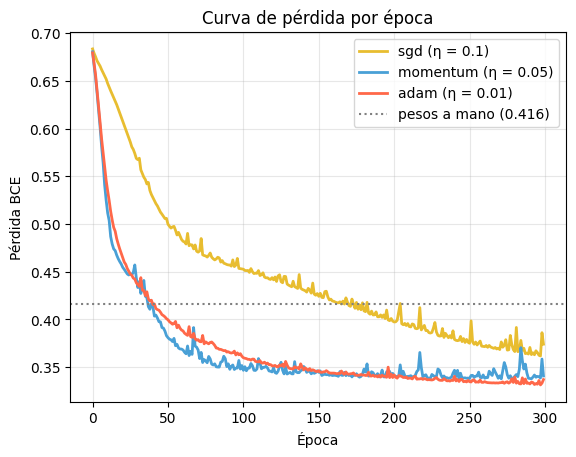

In [9]:
colores = {"sgd": "#E8BD30", "momentum": "#49A0D6", "adam": "#FF6849"}
for opt, lr in configuraciones:
    plt.plot(historiales[opt], label=f"{opt} (η = {lr})", color=colores[opt], linewidth=2)
plt.axhline(0.416, color="gray", linestyle=":", label="pesos a mano (0.416)")
plt.xlabel("Época")
plt.ylabel("Pérdida BCE")
plt.title("Curva de pérdida por época")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Lectura** (pérdida: 0 a +∞ → 0 = deseado; accuracy: 0 a 1 → 1 = deseado):

* **Momentum** y **Adam** bajan mucho más rápido que SGD: en la época 50 Momentum (0.383) ya casi alcanza la pérdida que SGD logra recién en la época 300 (0.374).
* Cada optimizador usa su propio η. Con β = 0.9, el paso efectivo de Momentum es mayor que el de SGD: parte de su ventaja viene de ahí.
* Las tres terminan con **menor pérdida** que los pesos fijados a mano (0.416, red 2 → 2 → 1), aunque los pesos a mano tienen mayor accuracy (0.92):
el entrenamiento **minimiza la pérdida, no la accuracy**, y la pérdida también premia probabilidades seguras cuando aciertan.
* Es **una sola corrida**: con otra semilla de inicialización el orden entre Momentum y Adam puede cambiar.
Lo que se repite es que ambos bajan antes que SGD. Prueba `semilla=1` y `semilla=3` en `entrenar()`.
* **¿Cuántas épocas?** Se entrena hasta que la curva se aplana. En la próxima clase Keras lo hará automáticamente.
* Ojo: estas medidas son sobre los mismos datos de entrenamiento; para evaluar de verdad hace falta un conjunto de prueba (próxima clase).

**Preguntas de la Parte A:**

1. ¿En qué época, aproximadamente, cada optimizador baja de 0.45 de pérdida? Léelo en el gráfico.

Observando la curva de perdida por epoca, Momentum desciende por debajo de 0.45 de perdida aproximadamente en la epoca 27. Adam lo consigue muy poco despues, alrededor de la epoca 33. Por su parte, SGD con descenso de gradiente estandar avanza a un ritmo mucho mas lento y requiere aproximadamente 118 epocas para cruzar el umbral de 0.45.

2. Entrena SGD con η = 0.5 y Adam con η = 0.001. ¿Qué cambia en cada curva? ¿Por qué?

Al entrenar SGD con una tasa alta de eta = 0.5, la curva desciende con rapidez inicial pero pronto comienza a oscilar de forma pronunciada e inestable, estancandose en una perdida final de 0.4509 (notablemente peor que el 0.374 obtenido con eta = 0.1) debido a que los pasos son excesivamente grandes y sobrepasan los minimos locales. En contraste, al entrenar Adam con una tasa reducida de eta = 0.001, la curva se vuelve extremadamente lenta: en la epoca 10 apenas alcanza 0.6809 y en la epoca 300 finaliza en 0.4411 sin llegar a converger al minimo que su potencial permite, ya que los pasos de actualizacion resultan demasiado cautelosos para el numero de epocas programado.

3. ¿Por qué la curva tiene pequeños picos de subida, si cada paso va «hacia abajo»? (Pista: mini-lotes.)

Los pequenos picos transitorios de subida se deben al uso de mini-lotes (mini-batch gradient descent). En cada paso, el gradiente se calcula y se actualiza en base a una muestra aleatoria de 32 estudiantes y no sobre los 200 datos completos. La direccion que reduce la perdida para un lote particular no necesariamente coincide con la direccion optima global para todo el conjunto de datos, introduciendo un componente de ruido estocastico que genera pequenas fluctuaciones ascendentes cuando se grafica la perdida media global al final de cada epoca.

# Parte B — Práctica Autónoma: Red de Regresión para el Puntaje de Crédito

**Contexto:** una cooperativa quiere estimar el **puntaje de crédito** (0 a 1) de sus clientes a partir de su nivel de
ingresos y de su historial de pagos (ambos ya normalizados entre 0 y 1). Es un problema de **regresión**:

* La capa de salida **no lleva activación** (salida lineal): el puntaje es un número, no una probabilidad.
* La pérdida es **MSE**.

En tu notebook, escribe el código que reemplace cada `# TODO` de esta guía; las pistas en los comentarios indican qué usar.

| Variable | Qué mide | Rol |
| --- | --- | --- |
| ingresos_norm | Nivel de ingresos (0 a 1) | Entrada x₁ |
| historial_norm | Calidad del historial de pagos (0 a 1) | Entrada x₂ |
| puntaje_credito | Puntaje de crédito (0 a 1) | Salida y |

## Bloque B1 · Datos

In [10]:
# TODO 1: carga credito_ecuador.csv en df_b
df_b = pd.read_csv("credito_ecuador.csv")

# TODO 2: crea X_b con las columnas "ingresos_norm" e "historial_norm" (.values)
#         y y_b con "puntaje_credito" como columna (200, 1)   pista: .reshape(-1, 1)
X_b = df_b[["ingresos_norm", "historial_norm"]].values
y_b = df_b["puntaje_credito"].values.reshape(-1, 1).astype(float)

# TODO 3: imprime X_b.shape, y_b.shape y el puntaje promedio (y_b.mean())
print("X_b.shape:", X_b.shape)
print("y_b.shape:", y_b.shape)
print("Puntaje promedio y_b.mean():", y_b.mean().round(4))

X_b.shape: (200, 2)
y_b.shape: (200, 1)
Puntaje promedio y_b.mean(): 0.5591


**Pregunta:** ¿por qué en esta parte no hace falta aplicar min-max a las entradas?

En esta parte no hace falta aplicar escalado min-max porque las variables predictoras de ingresos y de historial crediticio ya se encuentran previamente normalizadas dentro del rango continuo de 0 a 1 en el archivo CSV original.

## Bloque B2 · Forward y backward de regresión

Solo cambian dos cosas respecto a la Parte A:

* **Forward:** la salida es $z^{(2)}$ directamente (sin Sigmoid).
* **Backward:** con MSE, la señal de error de la salida es $\delta^{(2)} = \dfrac{2\,(\hat{y}-y)}{n}$.
El 2 viene de derivar el cuadrado: $\dfrac{d}{d\hat{y}}(\hat{y}-y)^2 = 2(\hat{y}-y)$. La capa oculta no cambia.

In [11]:
# TODO 4: define forward_regresion(X, params): igual que forward() del Bloque A4,
#         pero SIN sigmoid en la salida. Debe devolver y_hat, z1, a1
def forward_regresion(X, params):
    z1 = X @ params["W1"] + params["b1"]
    a1 = relu(z1)
    y_hat = a1 @ params["W2"] + params["b2"]    # salida lineal directa, sin sigmoid
    return y_hat, z1, a1

# TODO 5: define backward_regresion(X, y, y_hat, z1, a1, W2): igual que backward() del Bloque A4,
#         cambiando solo la primera línea por  d2 = 2 * (y_hat - y) / n
def backward_regresion(X, y, y_hat, z1, a1, W2):
    n = len(X)
    d2 = 2 * (y_hat - y) / n                     # derivada analítica de MSE
    dW2 = a1.T @ d2
    db2 = d2.sum(axis=0)
    d1 = (d2 @ W2.T) * d_relu(z1)
    dW1 = X.T @ d1
    db1 = d1.sum(axis=0)
    return dW1, db1, dW2, db2

# TODO 6: verifica tu gradiente con la derivada numérica (como en el Bloque A4):
#         params_b = inicializar_pesos(2, 8, 1)
#         elige el peso de W1 con mayor |gradiente| y compara backward_regresion con la
#         derivada numérica usando mse() (el error relativo debe ser casi 0)
params_b = inicializar_pesos(2, 8, 1, semilla=0)
y_hat_b, z1_b, a1_b = forward_regresion(X_b, params_b)
dW1_b, db1_b, dW2_b, db2_b = backward_regresion(X_b, y_b, y_hat_b, z1_b, a1_b, params_b["W2"])

h = 1e-4
i, j = np.unravel_index(np.abs(dW1_b).argmax(), dW1_b.shape)
p_mas_b = {k: v.copy() for k, v in params_b.items()}
p_menos_b = {k: v.copy() for k, v in params_b.items()}
p_mas_b["W1"][i, j] += h
p_menos_b["W1"][i, j] -= h

num_b = (mse(y_b, forward_regresion(X_b, p_mas_b)[0]) - mse(y_b, forward_regresion(X_b, p_menos_b)[0])) / (2 * h)
err_rel_b = abs(dW1_b[i, j] - num_b) / abs(num_b)

print(f"Peso W1[{i}, {j}]")
print(f"Backpropagation:   {dW1_b[i, j]:.6f}")
print(f"Derivada numérica: {num_b:.6f}")
print(f"Error relativo:    {err_rel_b:.1e}")

Peso W1[1, 3]
Backpropagation:   -0.354281
Derivada numérica: -0.354281
Error relativo:    2.3e-13


**Preguntas:**

1. ¿Qué pasaría con las predicciones si dejaras Sigmoid en la salida y un cliente tuviera puntaje real mayor que 1?

Si se mantuviera la funcion Sigmoid en la capa de salida, la red quedaria matematicamente limitada a emitir predicciones estrictamente contenidas en el intervalo abierto (0, 1). Si un cliente tuviera un puntaje real mayor que 1 (o si en el futuro la escala crediticia se ampliara a valores superiores), el modelo jamas podria predecir dicho valor. La neurona de salida entraria en una zona de saturacion positiva extrema donde su derivada se aproxima a cero, impidiendo que el gradiente fluya y haciendo imposible reducir el error para esos valores.

2. Si olvidas el 2 en `d2`, ¿la red igual aprende? ¿Qué efecto tiene sobre el tamaño del paso? (Pista: es como usar η/2.)

Si se omite el factor 2 en el calculo de d2, la red neuronal continua aprendiendo con total normalidad porque la direccion del vector gradiente no se altera en lo mas minimo. El unico efecto practico es que la magnitud del gradiente resultante se reduce exactamente a la mitad, lo que equivale matematicamente a entrenar el modelo utilizando una tasa de aprendizaje efectiva dividida para dos (eta sobre dos), dando pasos mas cortos pero en el sentido correcto.

## Bloque B3 · Entrenamiento con 4 tasas de aprendizaje

In [12]:
# TODO 7: define entrenar_regresion(X, y, lr, epocas=300, tamano_lote=32, semilla=0):
#         copia entrenar() del Bloque A5 con optimizador "sgd" y cambia:
#           - forward  -> forward_regresion
#           - backward -> backward_regresion
#           - la pérdida de cada época -> mse(y, forward_regresion(X, params)[0])
#         Debe devolver params, historial
def entrenar_regresion(X, y, lr, epocas=300, tamano_lote=32, semilla=0):
    params = inicializar_pesos(X.shape[1], 8, 1, semilla)
    rng = np.random.default_rng(1)
    historial = []

    for epoca in range(epocas):
        orden = rng.permutation(len(X))
        for inicio in range(0, len(X), tamano_lote):
            lote = orden[inicio:inicio + tamano_lote]
            y_hat, z1, a1 = forward_regresion(X[lote], params)
            dW1, db1, dW2, db2 = backward_regresion(X[lote], y[lote], y_hat, z1, a1, params["W2"])
            grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
            for k in params:
                params[k] -= lr * grads[k]
        historial.append(mse(y, forward_regresion(X, params)[0]))
    return params, historial

# TODO 8: para cada lr de learning_rates entrena 300 épocas y guarda el historial en resultados_b[lr]
#         pista: with np.errstate(all="ignore"):   (evita avisos si la pérdida crece mucho)
learning_rates = [1.0, 0.1, 0.01, 0.001]
resultados_b = {}
filas_b = []

for lr in learning_rates:
    with np.errstate(all="ignore"):
        params_reg, hist_reg = entrenar_regresion(X_b, y_b, lr=lr)
    resultados_b[lr] = hist_reg
    filas_b.append([lr, hist_reg[9], hist_reg[299]])

# TODO 9: muestra un DataFrame con columnas "η", "MSE época 10", "MSE época 300"
tabla_b = pd.DataFrame(filas_b, columns=["η", "MSE época 10", "MSE época 300"])
tabla_b

,η,MSE época 10,MSE época 300
0,1.000,8.859129,36.642635
1,0.100,0.008448,0.002331
2,0.010,0.017269,0.003043
3,0.001,0.173738,0.014114


## Bloque B4 · Gráfico comparativo

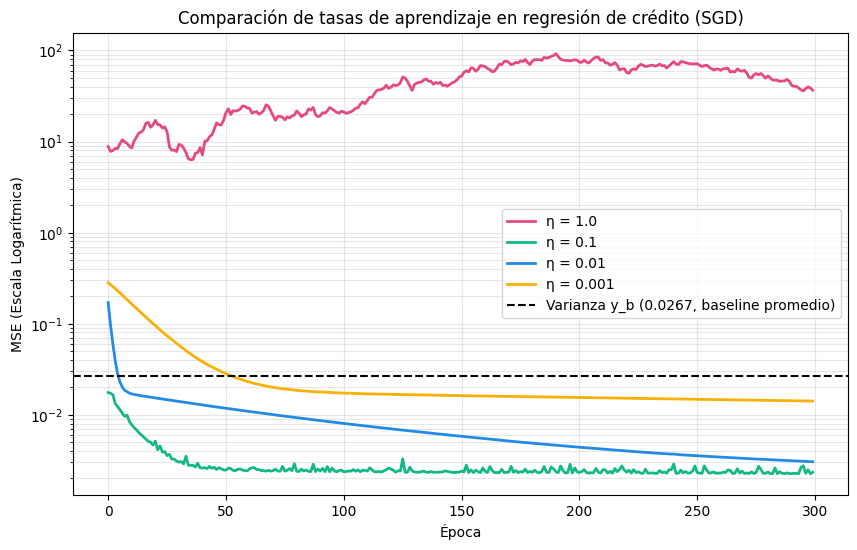

In [13]:
# TODO 10: grafica las 4 curvas de resultados_b en un mismo gráfico (una por lr, con label)
#          usa escala logarítmica en el eje y: plt.yscale("log")
#          agrega una línea horizontal con la varianza de y_b (y_b.var()): es el MSE de predecir
#          siempre el promedio. Un buen modelo debe quedar muy por debajo de esa línea.
colores_b = {1.0: "#E64980", 0.1: "#12B886", 0.01: "#228BE6", 0.001: "#FAB005"}

plt.figure(figsize=(10, 6))
for lr in learning_rates:
    plt.plot(resultados_b[lr], label=f"η = {lr}", color=colores_b[lr], linewidth=2)

plt.axhline(y_b.var(), color="black", linestyle="--", linewidth=1.5,
            label=f"Varianza y_b ({y_b.var():.4f}, baseline promedio)")

plt.yscale("log")
plt.xlabel("Época")
plt.ylabel("MSE (Escala Logarítmica)")
plt.title("Comparación de tasas de aprendizaje en regresión de crédito (SGD)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

**Preguntas** (MSE: 0 a +∞ → 0 = deseado):

1. Describe cada curva: ¿cuál diverge (la pérdida sube), cuál es la mejor y cuáles son demasiado lentas?

La curva con eta = 1.0 diverge claramente, subiendo de forma inestable desde un MSE de 8.859 en la epoca 10 hasta superar 36.642 en la epoca 300, manteniendose muy por encima de la linea base de varianza debido a pasos descomunales que desestabilizan los pesos. La curva con eta = 0.1 es la mejor de todas: desciende velozmente en pocas epocas muy por debajo de la varianza base, logrando el menor error cuadratico medio final (0.0023). Por su parte, las curvas con eta = 0.01 y eta = 0.001 presentan un aprendizaje monotono pero excesivamente lento; mientras que eta = 0.01 logra un valor aceptable hacia el final (0.0030), la curva con eta = 0.001 es demasiado lenta y tras 300 epocas apenas se ubica en 0.0141, todavia muy lejos de converger al minimo.

2. Con η = 0.001, ¿cuántas épocas más crees que harían falta para alcanzar a η = 0.1? ¿Vale la pena?

Con eta = 0.001 se necesitarian aproximadamente entre 1500 y 2500 epocas adicionales para alcanzar el nivel de perdida que eta = 0.1 logra comodamente en 300 epocas. Definitivamente no vale la pena asumir ese costo computacional y tiempo de espera adicional, ya que la solucion optima consiste simplemente en calibrar una tasa de aprendizaje adecuada como eta = 0.1 desde el principio.

3. ¿Cuál η elegirías y por qué? Calcula la raíz del MSE final (RMSE) de ese modelo: ¿qué error típico tiene en puntos de puntaje?

Se elegiria eta = 0.1 porque exhibe la convergencia mas rapida y alcanza el MSE final mas bajo (0.002331). Calculando la raiz del error cuadratico medio se obtiene un RMSE de raiz cuadrada de 0.002331 igual a 0.0483. Esto significa que el error tipico de prediccion de la red es de apenas 0.0483 unidades en la escala de 0 a 1, o aproximadamente 4.83 puntos si se expresa en una escala estandar de puntaje crediticio de 0 a 100, indicando una notable precision predictiva.

## Bloque B5 · Adam y reflexión

In [14]:
# TODO 11: crea entrenar_regresion_adam copiando entrenar_regresion y agregando Adam desde entrenar() del Bloque A5:
#          - antes del bucle: la creación de m, v (diccionarios de ceros) y t = 0
#          - en cada lote: t += 1
#          - las 5 líneas de actualización de Adam (en lugar de params[k] -= lr * grads[k])
#          Entrena con lr = 0.01 durante 300 épocas
def entrenar_regresion_adam(X, y, lr=0.01, epocas=300, tamano_lote=32, semilla=0):
    params = inicializar_pesos(X.shape[1], 8, 1, semilla)
    m = {k: np.zeros_like(w) for k, w in params.items()}
    v = {k: np.zeros_like(w) for k, w in params.items()}
    t = 0
    rng = np.random.default_rng(1)
    historial = []

    for epoca in range(epocas):
        orden = rng.permutation(len(X))
        for inicio in range(0, len(X), tamano_lote):
            lote = orden[inicio:inicio + tamano_lote]
            y_hat, z1, a1 = forward_regresion(X[lote], params)
            dW1, db1, dW2, db2 = backward_regresion(X[lote], y[lote], y_hat, z1, a1, params["W2"])
            grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
            t += 1
            for k in params:
                g = grads[k]
                m[k] = 0.9 * m[k] + 0.1 * g
                v[k] = 0.999 * v[k] + 0.001 * g ** 2
                m_hat = m[k] / (1 - 0.9 ** t)
                v_hat = v[k] / (1 - 0.999 ** t)
                params[k] -= lr * m_hat / (np.sqrt(v_hat) + 1e-8)
        historial.append(mse(y, forward_regresion(X, params)[0]))
    return params, historial

params_adam_b, hist_adam_b = entrenar_regresion_adam(X_b, y_b, lr=0.01, epocas=300)

# TODO 12: compara en una tabla el MSE de la época 10 y de la época 300 de:
#          SGD con el mejor η del Bloque B3 vs Adam con η = 0.01
mejor_sgd_lr = 0.1
tabla_comp = pd.DataFrame([
    ["SGD (η = 0.1)", resultados_b[mejor_sgd_lr][9], resultados_b[mejor_sgd_lr][-1]],
    ["Adam (η = 0.01)", hist_adam_b[9], hist_adam_b[-1]]
], columns=["Optimizador", "MSE época 10", "MSE época 300"])
tabla_comp

,Optimizador,MSE época 10,MSE época 300
0,SGD (η = 0.1),0.008448,0.002331
1,Adam (η = 0.01),0.004884,0.002288


**Preguntas de reflexión** (responde en celdas de texto):

1. ¿Adam supera al mejor SGD en esta red? ¿Coincide con lo observado en la Parte A?

Si, Adam supera al mejor SGD en rapidez de convergencia durante las fases tempranas del entrenamiento: en la epoca 10 Adam alcanza un MSE de 0.0049 frente a 0.0084 de SGD (casi la mitad del error), y al cabo de 300 epocas logra un error final ligeramente superior o equivalente (0.002288 frente a 0.002331). Este comportamiento coincide plenamente con lo observado en la Parte A, donde los metodos adaptativos y con momento reducen la funcion de perdida mucho mas rapido y con trayectorias mas estables que el descenso por gradiente estocastico basico.

2. Explica con tus palabras, sin fórmulas, qué hace backpropagation y por qué recorre la red **de atrás hacia adelante**.

Backpropagation es el proceso por el cual una red neuronal aprende a partir de sus propios errores. Comienza evaluando la respuesta final producida por la red contra la respuesta real deseada para cuantificar cuanto se equivoco. Luego recorre la arquitectura en sentido inverso, desde la capa de salida hacia la capa de entrada, porque para determinar la cuota de responsabilidad que tuvo una neurona interna en el error global, primero es indispensable conocer el error de todas las neuronas posteriores a las que envio informacion. Al viajar de atras hacia adelante mediante la regla de la cadena, propaga el error capa por capa y calcula con precision en que direccion y magnitud debe modificarse cada peso de la red para reducir el fallo en la siguiente ocasion.

3. Un compañero entrena una red y la pérdida aparece como `nan` desde la época 3. ¿Qué hiperparámetro revisarías primero y por qué?

El primer hiperparametro a verificar de inmediato es la tasa de aprendizaje (learning rate, eta). Cuando la tasa de aprendizaje se configura con un valor excesivamente grande, las actualizaciones de los pesos son desproporcionadas y provocan una explosion del gradiente. Los parametros comienzan a crecer hacia magnitudes numericas gigantescas, hasta que alguna operacion matricial, exponencial o de calculo de error excede la capacidad de representacion de punto flotante de la computadora y genera un desbordamiento numerico hacia infinito, el cual inmediatamente contamina las demas operaciones matriciales convirtiendose en NaN (Not a Number). Reducir la tasa de aprendizaje en uno o dos ordenes de magnitud resuelve este problema en la gran mayoria de los casos.

## Conclusiones

* La **función de pérdida** mide el error: MSE para regresión, entropía cruzada para clasificación.
* El **gradiente** indica cómo cambia la pérdida con cada peso; el **descenso de gradiente** da pasos en sentido contrario.
* **Backpropagation** calcula todos los gradientes con la regla de la cadena, de la salida hacia la entrada.
* La **tasa de aprendizaje** decide el tamaño del paso: muy grande diverge, muy pequeña es lenta.
* **Momentum** y **Adam** aceleran el entrenamiento respecto a SGD; Adam es la opción por defecto.